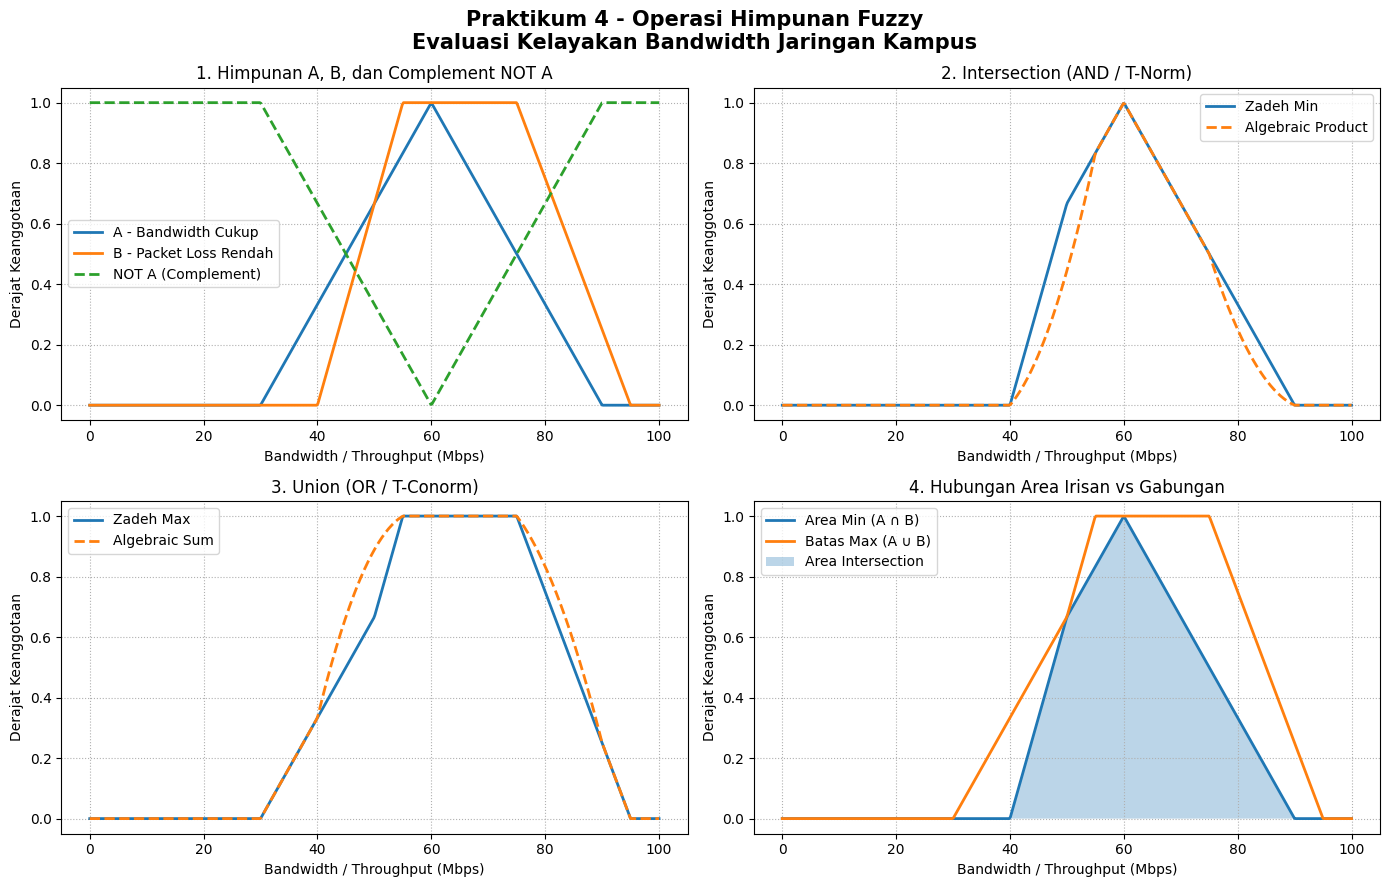



HASIL PENGUJIAN OPERASI HIMPUNAN FUZZY
Nilai   A           B           Min         Product     Max         Alg. Sum    NOT A       
----------------------------------------------------------------------------------------------------
35      0.1667      0.0000      0.0000      0.0000      0.1667      0.1667      0.8333      
50      0.6667      0.6667      0.6667      0.4444      0.6667      0.8889      0.3333      
65      0.8333      1.0000      0.8333      0.8333      1.0000      1.0000      0.1667      
80      0.3333      0.7500      0.3333      0.2500      0.7500      0.8333      0.6667      


In [ ]:
import numpy as np
import matplotlib.pyplot as plt


# ==========================================================
# 1. FUNGSI KEANGGOTAAN HIMPUNAN A
#    Ketersediaan Bandwidth Cukup
#    Model Segitiga [30, 60, 90]
# ==========================================================

def membership_A(x):
    x = np.asarray(x)

    return np.maximum(
        0,
        np.minimum(
            (x - 30) / (60 - 30),
            (90 - x) / (90 - 60)
        )
    )


# ==========================================================
# 2. FUNGSI KEANGGOTAAN HIMPUNAN B
#    Packet Loss Rendah
#    Model Trapesium [40, 55, 75, 95]
# ==========================================================

def membership_B(x):
    x = np.asarray(x)

    return np.maximum(
        0,
        np.minimum(
            np.minimum(
                (x - 40) / (55 - 40),
                1
            ),
            (95 - x) / (95 - 75)
        )
    )


# ==========================================================
# 3. OPERASI FUZZY
# ==========================================================

# Intersection / AND
def zadeh_min(mu_a, mu_b):
    return np.minimum(mu_a, mu_b)


def algebraic_product(mu_a, mu_b):
    return mu_a * mu_b


# Union / OR
def zadeh_max(mu_a, mu_b):
    return np.maximum(mu_a, mu_b)


def algebraic_sum(mu_a, mu_b):
    return mu_a + mu_b - (mu_a * mu_b)


# Complement / NOT
def complement(mu_a):
    return 1 - mu_a


# ==========================================================
# 4. MEMBUAT SEMESTA PEMBICARAAN
#    Bandwidth / Throughput 0 - 100 Mbps
# ==========================================================

x = np.linspace(0, 100, 500)

mu_A = membership_A(x)
mu_B = membership_B(x)


# ==========================================================
# 5. MENGHITUNG OPERASI
# ==========================================================

# Intersection
intersection_min = zadeh_min(mu_A, mu_B)
intersection_product = algebraic_product(mu_A, mu_B)

# Union
union_max = zadeh_max(mu_A, mu_B)
union_sum = algebraic_sum(mu_A, mu_B)

# Complement A
not_A = complement(mu_A)


# ==========================================================
# 6. MEMBUAT GRAFIK 4 PANEL
# ==========================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

fig.suptitle(
    "Praktikum 4 - Operasi Himpunan Fuzzy\n"
    "Evaluasi Kelayakan Bandwidth Jaringan Kampus",
    fontsize=15,
    fontweight="bold"
)


# ----------------------------------------------------------
# GRAFIK 1
# Himpunan A, B, dan Complement A
# ----------------------------------------------------------

axes[0, 0].plot(
    x, mu_A,
    label="A - Bandwidth Cukup",
    linewidth=2
)

axes[0, 0].plot(
    x, mu_B,
    label="B - Packet Loss Rendah",
    linewidth=2
)

axes[0, 0].plot(
    x, not_A,
    label="NOT A (Complement)",
    linestyle="--",
    linewidth=2
)

axes[0, 0].set_title("1. Himpunan A, B, dan Complement NOT A")
axes[0, 0].set_xlabel("Bandwidth / Throughput (Mbps)")
axes[0, 0].set_ylabel("Derajat Keanggotaan")
axes[0, 0].set_ylim(-0.05, 1.05)
axes[0, 0].grid(True, linestyle=":")
axes[0, 0].legend()


# ----------------------------------------------------------
# GRAFIK 2
# Intersection / AND
# Zadeh Min dan Algebraic Product
# ----------------------------------------------------------

axes[0, 1].plot(
    x, intersection_min,
    label="Zadeh Min",
    linewidth=2
)

axes[0, 1].plot(
    x, intersection_product,
    label="Algebraic Product",
    linestyle="--",
    linewidth=2
)

axes[0, 1].set_title("2. Intersection (AND / T-Norm)")
axes[0, 1].set_xlabel("Bandwidth / Throughput (Mbps)")
axes[0, 1].set_ylabel("Derajat Keanggotaan")
axes[0, 1].set_ylim(-0.05, 1.05)
axes[0, 1].grid(True, linestyle=":")
axes[0, 1].legend()


# ----------------------------------------------------------
# GRAFIK 3
# Union / OR
# Zadeh Max dan Algebraic Sum
# ----------------------------------------------------------

axes[1, 0].plot(
    x, union_max,
    label="Zadeh Max",
    linewidth=2
)

axes[1, 0].plot(
    x, union_sum,
    label="Algebraic Sum",
    linestyle="--",
    linewidth=2
)

axes[1, 0].set_title("3. Union (OR / T-Conorm)")
axes[1, 0].set_xlabel("Bandwidth / Throughput (Mbps)")
axes[1, 0].set_ylabel("Derajat Keanggotaan")
axes[1, 0].set_ylim(-0.05, 1.05)
axes[1, 0].grid(True, linestyle=":")
axes[1, 0].legend()


# ----------------------------------------------------------
# GRAFIK 4
# Perbandingan Area Intersection dan Union
# ----------------------------------------------------------

axes[1, 1].plot(
    x, intersection_min,
    label="Area Min (A ∩ B)",
    linewidth=2
)

axes[1, 1].plot(
    x, union_max,
    label="Batas Max (A ∪ B)",
    linewidth=2
)

axes[1, 1].fill_between(
    x,
    0,
    intersection_min,
    alpha=0.3,
    label="Area Intersection"
)

axes[1, 1].set_title("4. Hubungan Area Irisan vs Gabungan")
axes[1, 1].set_xlabel("Bandwidth / Throughput (Mbps)")
axes[1, 1].set_ylabel("Derajat Keanggotaan")
axes[1, 1].set_ylim(-0.05, 1.05)
axes[1, 1].grid(True, linestyle=":")
axes[1, 1].legend()


# ==========================================================
# 7. MERAPIKAN DAN MENYIMPAN GRAFIK
# ==========================================================

plt.tight_layout()

plt.savefig(
    "operasi_himpunan_fuzzy_P4.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ==========================================================
# 8. PENGUJIAN 4 NILAI THROUGHPUT
#    Sesuai instruksi Tugas Praktikum 4
# ==========================================================

test_values = [35, 50, 65, 80]

print("\n")
print("HASIL PENGUJIAN OPERASI HIMPUNAN FUZZY")
print("=" * 100)

print(
    f"{'Nilai':<8}"
    f"{'A':<12}"
    f"{'B':<12}"
    f"{'Min':<12}"
    f"{'Product':<12}"
    f"{'Max':<12}"
    f"{'Alg. Sum':<12}"
    f"{'NOT A':<12}"
)

print("-" * 100)

for value in test_values:

    a = float(membership_A(value))
    b = float(membership_B(value))

    min_value = float(zadeh_min(a, b))
    product_value = float(algebraic_product(a, b))

    max_value = float(zadeh_max(a, b))
    sum_value = float(algebraic_sum(a, b))

    not_a_value = float(complement(a))

    print(
        f"{value:<8}"
        f"{a:<12.4f}"
        f"{b:<12.4f}"
        f"{min_value:<12.4f}"
        f"{product_value:<12.4f}"
        f"{max_value:<12.4f}"
        f"{sum_value:<12.4f}"
        f"{not_a_value:<12.4f}"
    )

print("=" * 100)